In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [48]:
import xgboost as xgb
from xgboost import XGBRegressor

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [4]:
df = pd.read_csv("Tetuan City power consumption.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (52416, 9)


In [5]:
df.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [7]:
print("Columns:")
print(df.columns.tolist())

Columns:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption']


In [8]:
print("\nData Types:")
print(df.dtypes)


Data Types:
DateTime                      object
Temperature                  float64
Humidity                     float64
Wind Speed                   float64
general diffuse flows        float64
diffuse flows                float64
Zone 1 Power Consumption     float64
Zone 2  Power Consumption    float64
Zone 3  Power Consumption    float64
dtype: object


In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
dtype: int64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   DateTime                   52416 non-null  object 
 1   Temperature                52416 non-null  float64
 2   Humidity                   52416 non-null  float64
 3   Wind Speed                 52416 non-null  float64
 4   general diffuse flows      52416 non-null  float64
 5   diffuse flows              52416 non-null  float64
 6   Zone 1 Power Consumption   52416 non-null  float64
 7   Zone 2  Power Consumption  52416 non-null  float64
 8   Zone 3  Power Consumption  52416 non-null  float64
dtypes: float64(8), object(1)
memory usage: 3.6+ MB


In [11]:
df.describe()

,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


In [12]:
print(df["DateTime"].head())
print("\nFirst date:", df["DateTime"].iloc[0])
print("Last date:", df["DateTime"].iloc[-1])

0    1/1/2017 0:00
1    1/1/2017 0:10
2    1/1/2017 0:20
3    1/1/2017 0:30
4    1/1/2017 0:40
Name: DateTime, dtype: object

First date: 1/1/2017 0:00
Last date: 12/30/2017 23:50


In [13]:
df["DateTime"] = pd.to_datetime(df["DateTime"])

print(df.dtypes["DateTime"])
print(df["DateTime"].head())

datetime64[ns]
0   2017-01-01 00:00:00
1   2017-01-01 00:10:00
2   2017-01-01 00:20:00
3   2017-01-01 00:30:00
4   2017-01-01 00:40:00
Name: DateTime, dtype: datetime64[ns]


In [14]:
df = df.sort_values("DateTime").reset_index(drop=True)

df.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [15]:
duplicates = df["DateTime"].duplicated().sum()

print("Duplicate DateTime rows:", duplicates)

Duplicate DateTime rows: 0


In [16]:
time_diff = df["DateTime"].diff().dropna()

print(time_diff.value_counts().head())

DateTime
0 days 00:10:00    52415
Name: count, dtype: int64


In [17]:
target = "Zone 1 Power Consumption"

print("Target column:", target)
print(df[target].describe())

Target column: Zone 1 Power Consumption
count    52416.000000
mean     32344.970564
std       7130.562564
min      13895.696200
25%      26310.668692
50%      32265.920340
75%      37309.018185
max      52204.395120
Name: Zone 1 Power Consumption, dtype: float64


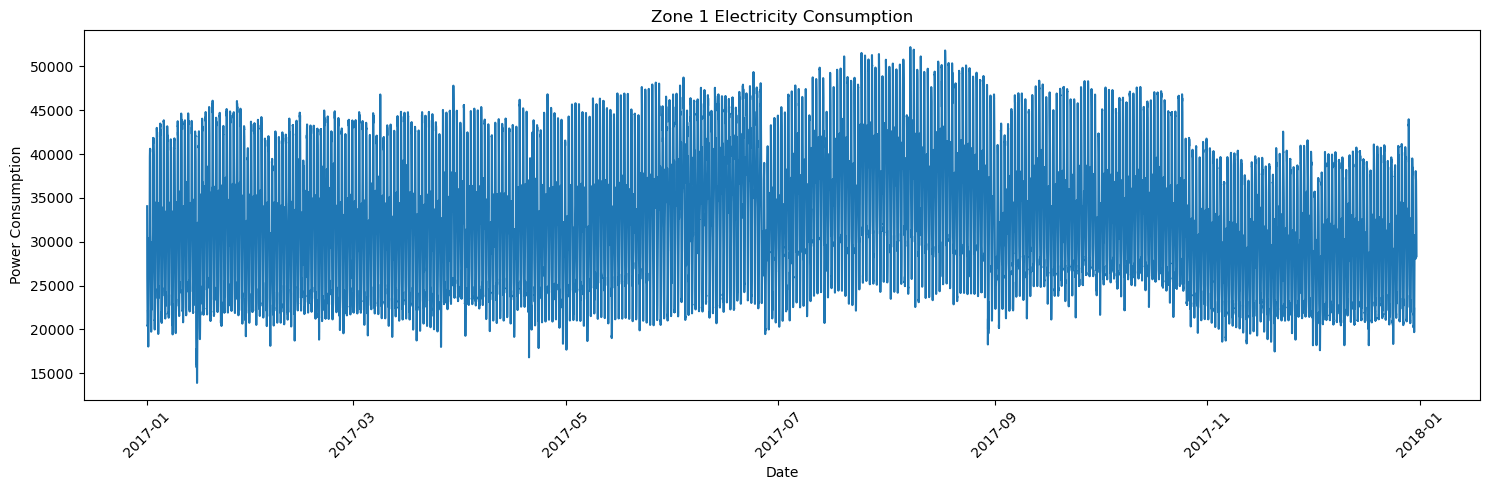

In [18]:
plt.figure(figsize=(15, 5))

plt.plot(df["DateTime"], df[target])

plt.title("Zone 1 Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Power Consumption")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

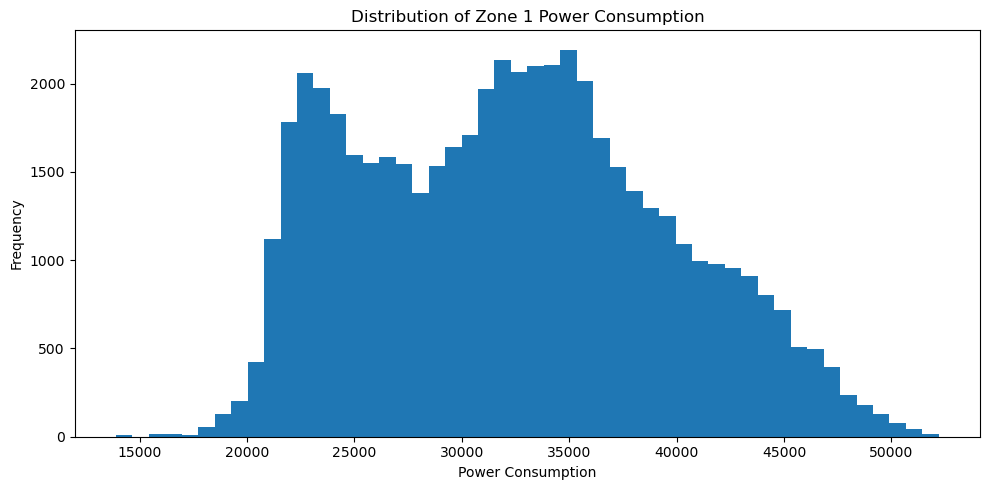

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df[target], bins=50)

plt.title("Distribution of Zone 1 Power Consumption")
plt.xlabel("Power Consumption")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [20]:
eda_df = df.copy()

eda_df["Hour"] = eda_df["DateTime"].dt.hour
eda_df["DayOfWeek"] = eda_df["DateTime"].dt.dayofweek

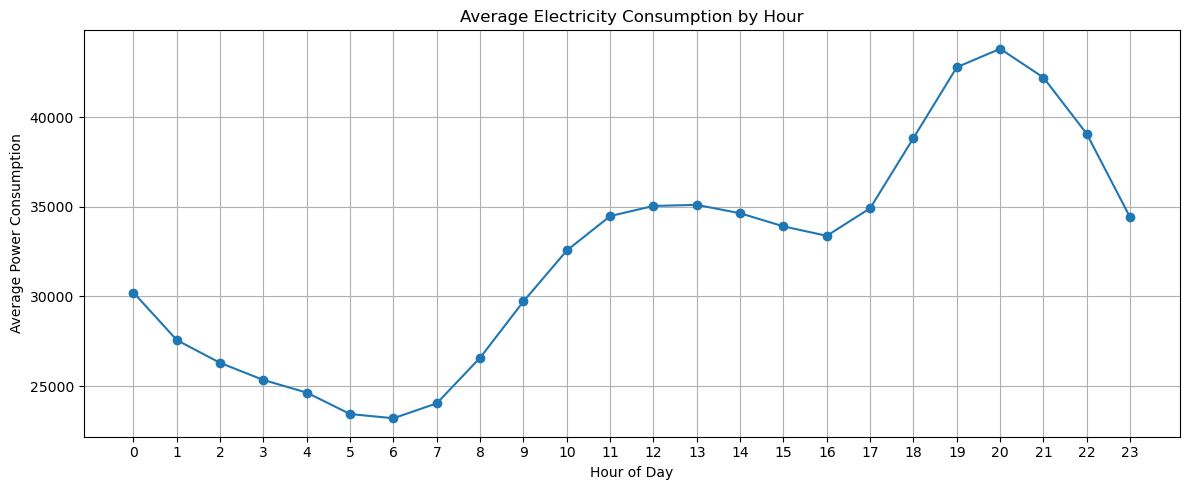

In [21]:
hourly_avg = eda_df.groupby("Hour")[target].mean()

plt.figure(figsize=(12, 5))

plt.plot(hourly_avg.index, hourly_avg.values, marker="o")

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power Consumption")
plt.xticks(range(24))

plt.grid(True)
plt.tight_layout()
plt.show()

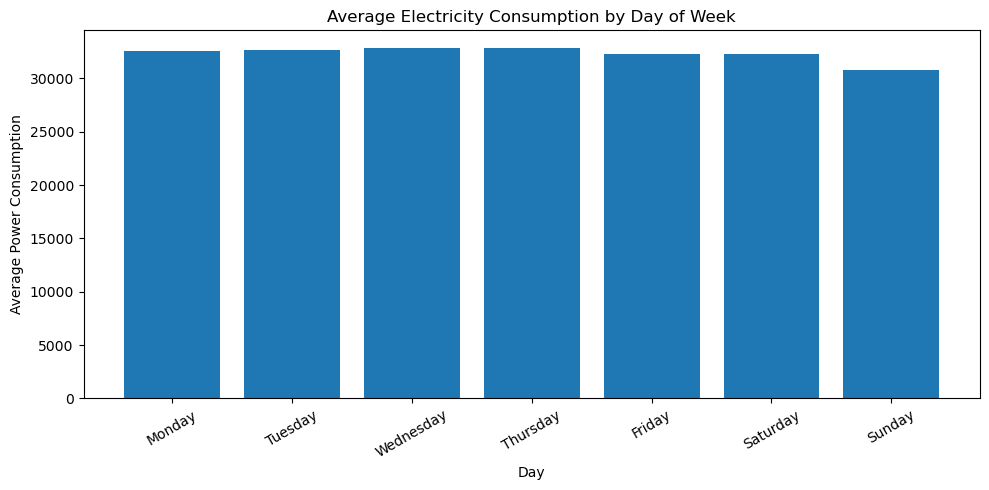

In [22]:
daily_avg = eda_df.groupby("DayOfWeek")[target].mean()

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10, 5))

plt.bar(days, daily_avg.values)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Power Consumption")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

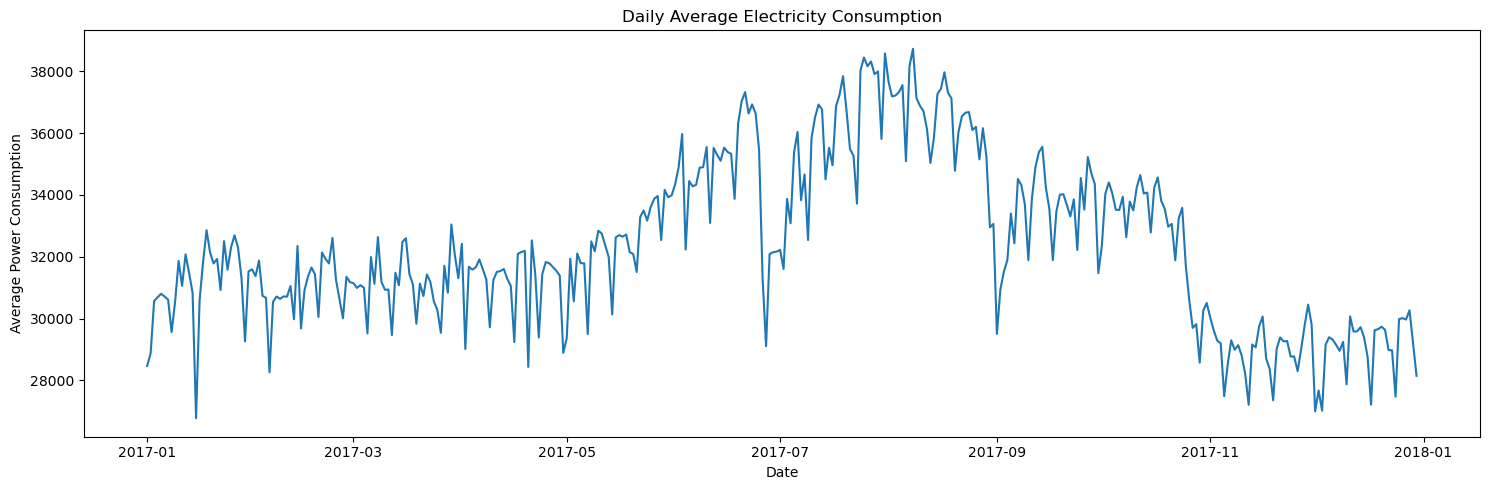

In [23]:
daily_consumption = (
    df.set_index("DateTime")[target]
    .resample("D")
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(daily_consumption.index, daily_consumption.values)

plt.title("Daily Average Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power Consumption")

plt.tight_layout()
plt.show()

In [24]:
hourly_df = (
    df.set_index("DateTime")
      .resample("1h")
      .mean()
      .reset_index()
)

print("Original shape:", df.shape)
print("Hourly shape:", hourly_df.shape)

hourly_df.head()

Original shape: (52416, 9)
Hourly shape: (8736, 9)


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.196833,75.066667,0.081833,0.063500,0.098833,29197.974683,18026.747720,19252.048193
1,2017-01-01 01:00:00,5.548833,77.583333,0.082000,0.056833,0.112500,24657.215190,16078.419453,17042.891567
2,2017-01-01 02:00:00,5.054333,78.933333,0.082333,0.063000,0.129167,22083.037973,14330.699088,15676.144578
3,2017-01-01 03:00:00,5.004333,77.083333,0.082833,0.059833,0.141000,20811.139240,13219.452887,14883.855422
4,2017-01-01 04:00:00,5.097667,74.050000,0.082333,0.058000,0.122833,20475.949367,12921.580547,14317.108433


In [25]:
print(hourly_df.isnull().sum())

DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
dtype: int64


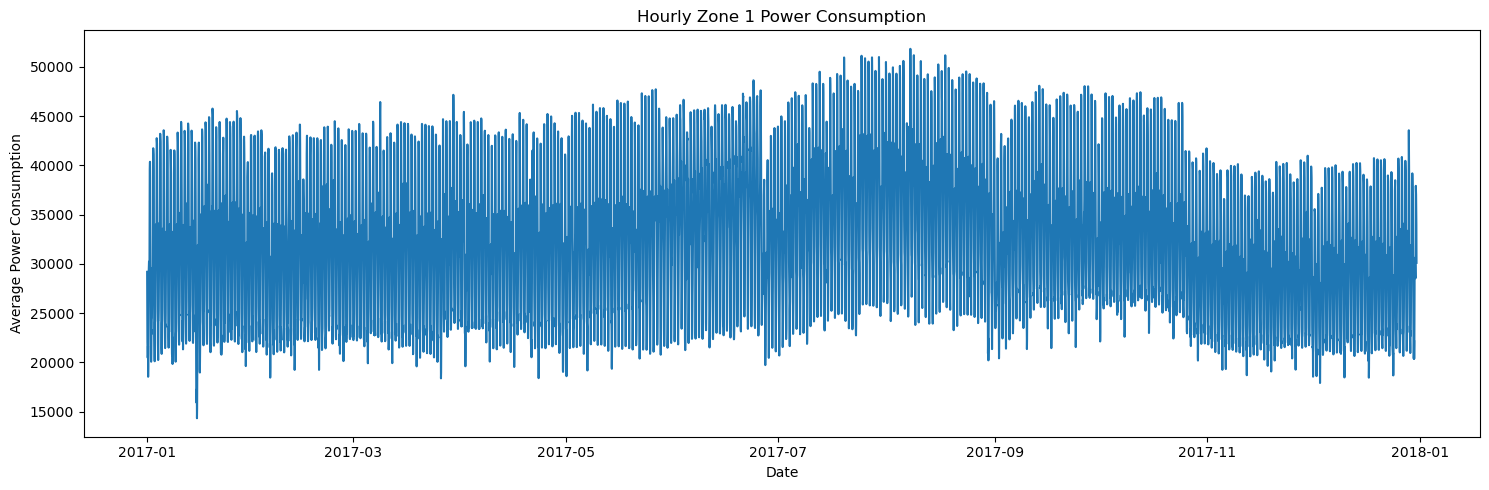

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_df["DateTime"],
    hourly_df[target]
)

plt.title("Hourly Zone 1 Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power Consumption")

plt.tight_layout()
plt.show()

In [27]:
top_10 = hourly_df.nlargest(10, target)[
    ["DateTime", target]
]

print(top_10)

                DateTime  Zone 1 Power Consumption
5252 2017-08-07 20:00:00              51844.261932
5276 2017-08-08 20:00:00              51192.186458
5492 2017-08-17 20:00:00              51185.793565
4916 2017-07-24 20:00:00              51138.338872
5036 2017-07-29 20:00:00              51010.764120
4988 2017-07-27 20:00:00              50973.554817
4796 2017-07-19 20:00:00              50965.049833
4940 2017-07-25 20:00:00              50886.378737
5204 2017-08-05 20:00:00              50614.694782
5324 2017-08-10 20:00:00              50597.647058


In [28]:
bottom_10 = hourly_df.nsmallest(10, target)[
    ["DateTime", target]
]

print(bottom_10)

                DateTime  Zone 1 Power Consumption
343  2017-01-15 07:00:00              14329.113923
344  2017-01-15 08:00:00              15346.835443
340  2017-01-15 04:00:00              15908.860762
341  2017-01-15 05:00:00              16288.607595
339  2017-01-15 03:00:00              16338.227847
342  2017-01-15 06:00:00              17296.202532
338  2017-01-15 02:00:00              17353.924050
8071 2017-12-03 07:00:00              17908.238277
345  2017-01-15 09:00:00              18377.721520
2022 2017-03-26 06:00:00              18380.936168


In [29]:
hourly_df["Hour"] = hourly_df["DateTime"].dt.hour

peak_by_hour = (
    hourly_df.groupby("Hour")[target]
    .mean()
    .sort_values(ascending=False)
)

print(peak_by_hour)

Hour
20    43822.590575
19    42795.919144
21    42216.478542
22    39068.635850
18    38846.130578
13    35112.272501
12    35052.519771
17    34924.975330
14    34643.598565
11    34487.628942
23    34409.579507
15    33911.996991
16    33385.204774
10    32566.456638
0     30217.235372
9     29725.358515
1     27565.533030
8     26583.262396
2     26292.688917
3     25338.122851
4     24633.576717
7     24038.353352
5     23437.577276
6     23203.597394
Name: Zone 1 Power Consumption, dtype: float64


In [30]:
print("Top 5 Peak Hours:")
print(peak_by_hour.head(5))

Top 5 Peak Hours:
Hour
20    43822.590575
19    42795.919144
21    42216.478542
22    39068.635850
18    38846.130578
Name: Zone 1 Power Consumption, dtype: float64


In [31]:
hourly_df.to_csv(
    "hourly_electricity_data.csv",
    index=False
)

print("Hourly dataset saved successfully!")

Hourly dataset saved successfully!


In [32]:
hourly_df["Hour"] = hourly_df["DateTime"].dt.hour
hourly_df["DayOfWeek"] = hourly_df["DateTime"].dt.dayofweek
hourly_df["Day"] = hourly_df["DateTime"].dt.day
hourly_df["Month"] = hourly_df["DateTime"].dt.month

hourly_df["IsWeekend"] = (
    hourly_df["DayOfWeek"] >= 5
).astype(int)

hourly_df.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Hour,DayOfWeek,Day,Month,IsWeekend
0,2017-01-01 00:00:00,6.196833,75.066667,0.081833,0.063500,0.098833,29197.974683,18026.747720,19252.048193,0,6,1,1,1
1,2017-01-01 01:00:00,5.548833,77.583333,0.082000,0.056833,0.112500,24657.215190,16078.419453,17042.891567,1,6,1,1,1
2,2017-01-01 02:00:00,5.054333,78.933333,0.082333,0.063000,0.129167,22083.037973,14330.699088,15676.144578,2,6,1,1,1
3,2017-01-01 03:00:00,5.004333,77.083333,0.082833,0.059833,0.141000,20811.139240,13219.452887,14883.855422,3,6,1,1,1
4,2017-01-01 04:00:00,5.097667,74.050000,0.082333,0.058000,0.122833,20475.949367,12921.580547,14317.108433,4,6,1,1,1


In [33]:
hourly_df["Lag_1"] = hourly_df[target].shift(1)
hourly_df["Lag_24"] = hourly_df[target].shift(24)
hourly_df["Lag_168"] = hourly_df[target].shift(168)

In [34]:
hourly_df["RollingMean_24"] = (
    hourly_df[target]
    .rolling(window=24)
    .mean()
)

hourly_df["RollingStd_24"] = (
    hourly_df[target]
    .rolling(window=24)
    .std()
)

In [35]:
print(hourly_df.isnull().sum())

DateTime                       0
Temperature                    0
Humidity                       0
Wind Speed                     0
general diffuse flows          0
diffuse flows                  0
Zone 1 Power Consumption       0
Zone 2  Power Consumption      0
Zone 3  Power Consumption      0
Hour                           0
DayOfWeek                      0
Day                            0
Month                          0
IsWeekend                      0
Lag_1                          1
Lag_24                        24
Lag_168                      168
RollingMean_24                23
RollingStd_24                 23
dtype: int64


In [37]:
hourly_df = hourly_df.dropna().reset_index(drop=True)

print("New shape:", hourly_df.shape)
print("\nRemaining missing values:")
print(hourly_df.isnull().sum())

New shape: (8568, 19)

Remaining missing values:
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
Hour                         0
DayOfWeek                    0
Day                          0
Month                        0
IsWeekend                    0
Lag_1                        0
Lag_24                       0
Lag_168                      0
RollingMean_24               0
RollingStd_24                0
dtype: int64


In [38]:
hourly_df.head()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Hour,DayOfWeek,Day,Month,IsWeekend,Lag_1,Lag_24,Lag_168,RollingMean_24,RollingStd_24
0,2017-01-08 00:00:00,14.273333,77.916667,0.0880,0.044667,0.123667,26633.924052,17421.276597,17871.807228,0,6,8,1,1,31526.075950,27193.924052,29197.974683,30589.367088,6582.663530
1,2017-01-08 01:00:00,14.441667,76.616667,0.0910,0.046500,0.137000,23640.506328,15492.401215,16057.831327,1,6,8,1,1,26633.924052,23961.518987,24657.215190,30575.991561,6597.026874
2,2017-01-08 02:00:00,14.216667,74.183333,0.0885,0.045833,0.123667,21817.721520,14072.340427,15021.686747,2,6,8,1,1,23640.506328,22588.354430,22083.037973,30543.881856,6639.335236
3,2017-01-08 03:00:00,13.990000,73.150000,0.0865,0.047000,0.164333,20831.392407,13240.729482,14500.240965,3,6,8,1,1,21817.721520,21849.113925,20811.139240,30501.476793,6700.253305
4,2017-01-08 04:00:00,13.505000,76.133333,0.0920,0.055000,0.135500,20688.607595,12976.899697,14200.481927,4,6,8,1,1,20831.392407,21502.784810,20475.949367,30467.552742,6749.674370


In [39]:
hourly_df.tail()

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Hour,DayOfWeek,Day,Month,IsWeekend,Lag_1,Lag_24,Lag_168,RollingMean_24,RollingStd_24
8563,2017-12-30 19:00:00,9.453333,62.406667,0.074667,0.052000,0.102000,37513.814957,32497.698680,16926.770708,19,5,30,12,1,37929.531053,38381.749048,39226.362485,28240.811153,6026.772274
8564,2017-12-30 20:00:00,9.041667,63.990000,0.080333,0.052667,0.105000,37008.871988,32020.251610,16998.799520,20,5,30,12,1,37513.814957,38146.514577,38234.727503,28193.409379,5949.452431
8565,2017-12-30 21:00:00,8.011667,69.675000,0.081500,0.073167,0.098333,35358.174905,30757.901197,16608.883553,21,5,30,12,1,37008.871988,36578.960708,36373.130543,28142.543304,5879.448121
8566,2017-12-30 22:00:00,7.598333,70.315000,0.081833,0.058667,0.108167,33993.409380,28477.447070,15614.885955,22,5,30,12,1,35358.174905,33705.449937,34008.618503,28154.541614,5891.575353
8567,2017-12-30 23:00:00,6.877500,72.900000,0.081500,0.060333,0.092667,30107.984788,25713.409022,14143.577428,23,5,30,12,1,33993.409380,30320.912548,30400.000000,28145.669624,5888.330654


In [36]:
features = [
    "Hour",
    "DayOfWeek",
    "Day",
    "Month",
    "IsWeekend",
    "Lag_1",
    "Lag_24",
    "Lag_168",
    "RollingMean_24",
    "RollingStd_24"
]

print(features)

['Hour', 'DayOfWeek', 'Day', 'Month', 'IsWeekend', 'Lag_1', 'Lag_24', 'Lag_168', 'RollingMean_24', 'RollingStd_24']


In [40]:
X = hourly_df[features]
y = hourly_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8568, 10)
y shape: (8568,)


In [41]:
split_index = int(len(hourly_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (6854, 10)
Testing data: (1714, 10)


In [42]:
print("Training period:")
print(hourly_df["DateTime"].iloc[0])
print("to")
print(hourly_df["DateTime"].iloc[split_index - 1])

print("\nTesting period:")
print(hourly_df["DateTime"].iloc[split_index])
print("to")
print(hourly_df["DateTime"].iloc[-1])

Training period:
2017-01-08 00:00:00
to
2017-10-20 13:00:00

Testing period:
2017-10-20 14:00:00
to
2017-12-30 23:00:00


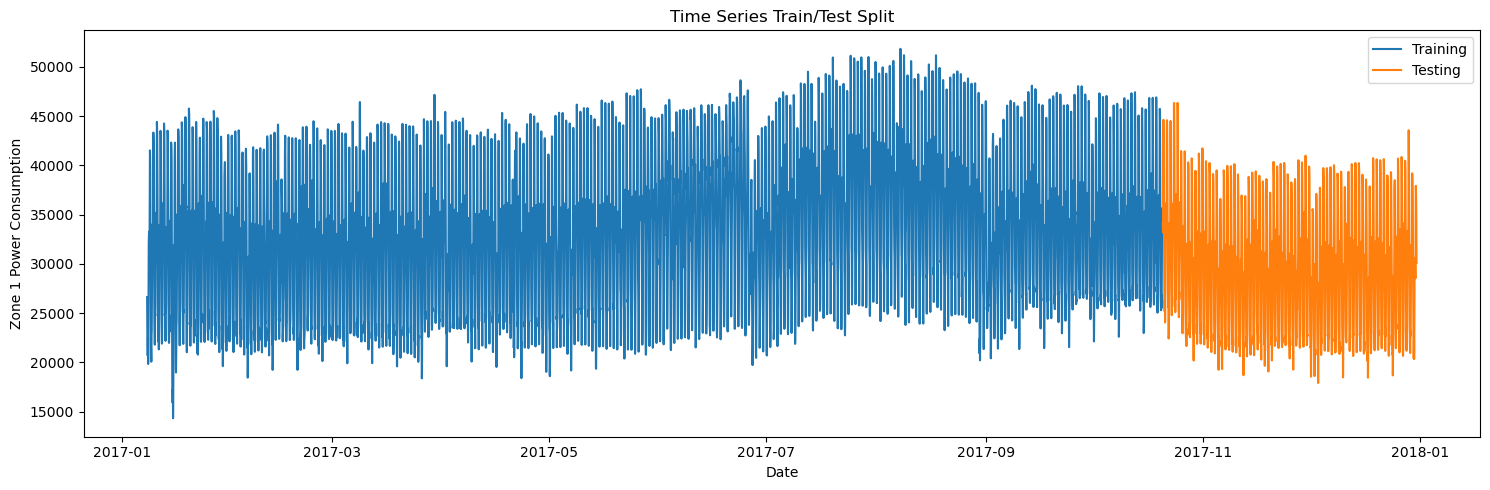

In [43]:
plt.figure(figsize=(15, 5))

plt.plot(
    hourly_df["DateTime"].iloc[:split_index],
    y_train,
    label="Training"
)

plt.plot(
    hourly_df["DateTime"].iloc[split_index:],
    y_test,
    label="Testing"
)

plt.title("Time Series Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Zone 1 Power Consumption")
plt.legend()

plt.tight_layout()
plt.show()

In [44]:
hourly_df["RollingMean_24"] = (
    hourly_df[target]
    .shift(1)
    .rolling(window=24)
    .mean()
)

hourly_df["RollingStd_24"] = (
    hourly_df[target]
    .shift(1)
    .rolling(window=24)
    .std()
)

In [45]:
print(hourly_df.isnull().sum())

DateTime                      0
Temperature                   0
Humidity                      0
Wind Speed                    0
general diffuse flows         0
diffuse flows                 0
Zone 1 Power Consumption      0
Zone 2  Power Consumption     0
Zone 3  Power Consumption     0
Hour                          0
DayOfWeek                     0
Day                           0
Month                         0
IsWeekend                     0
Lag_1                         0
Lag_24                        0
Lag_168                       0
RollingMean_24               24
RollingStd_24                24
dtype: int64


In [46]:
hourly_df = hourly_df.dropna().reset_index(drop=True)

print("Final dataset shape:", hourly_df.shape)
print("\nMissing values:")
print(hourly_df.isnull().sum())

Final dataset shape: (8544, 19)

Missing values:
DateTime                     0
Temperature                  0
Humidity                     0
Wind Speed                   0
general diffuse flows        0
diffuse flows                0
Zone 1 Power Consumption     0
Zone 2  Power Consumption    0
Zone 3  Power Consumption    0
Hour                         0
DayOfWeek                    0
Day                          0
Month                        0
IsWeekend                    0
Lag_1                        0
Lag_24                       0
Lag_168                      0
RollingMean_24               0
RollingStd_24                0
dtype: int64


In [47]:
X = hourly_df[features]
y = hourly_df[target]

split_index = int(len(hourly_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (6835, 10)
X_test : (1709, 10)
y_train: (6835,)
y_test : (1709,)


In [49]:
model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [50]:
y_pred = model.predict(X_test)

print("Predictions generated:", len(y_pred))

Predictions generated: 1709


In [52]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

mape = np.mean(
    np.abs((y_test - y_pred) / y_test)
) * 100

print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE : 903.7180066647162
RMSE: 1217.7479339212312
MAPE: 3.151022411858147 %


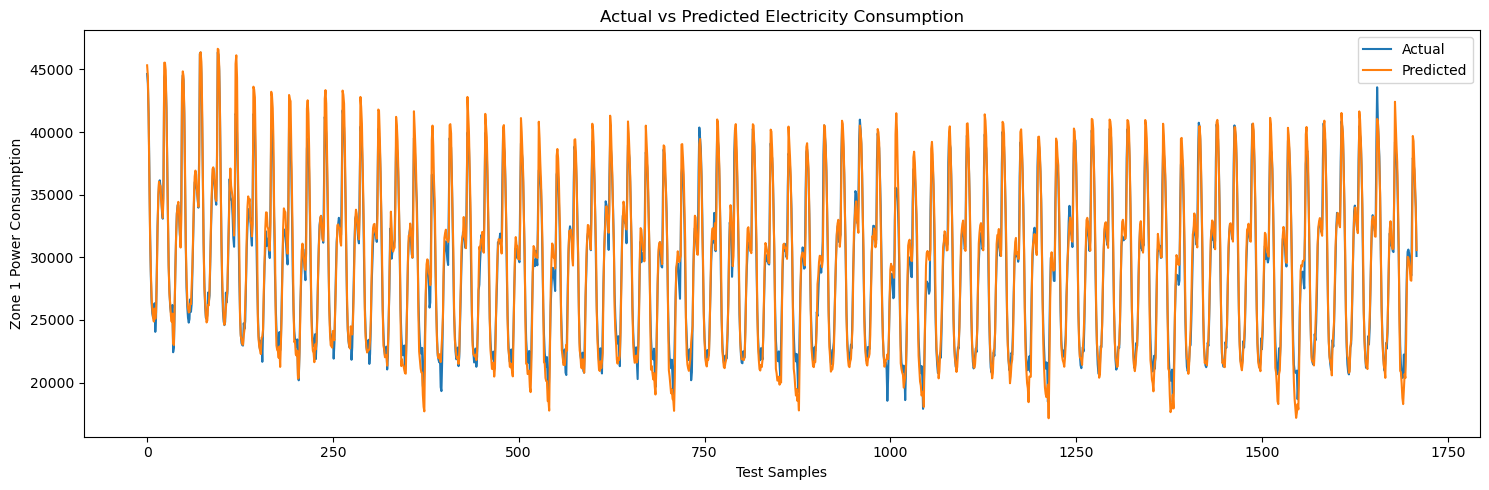

In [53]:
plt.figure(figsize=(15, 5))

plt.plot(
    y_test.values,
    label="Actual"
)

plt.plot(
    y_pred,
    label="Predicted"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Samples")
plt.ylabel("Zone 1 Power Consumption")
plt.legend()

plt.tight_layout()
plt.show()

In [54]:
results = pd.DataFrame({
    "DateTime": hourly_df["DateTime"].iloc[split_index:].values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Error"] = (
    results["Actual"] - results["Predicted"]
)

results.head(20)

,DateTime,Actual,Predicted,Error
0,2017-10-20 19:00:00,44637.899343,45326.398438,-688.499094
1,2017-10-20 20:00:00,43882.713347,44456.085938,-573.372591
2,2017-10-20 21:00:00,41498.468270,41149.867188,348.601083
3,2017-10-20 22:00:00,37074.485777,36107.480469,967.005308
4,2017-10-20 23:00:00,31948.884027,31519.789062,429.094964
5,2017-10-21 00:00:00,28527.964990,28944.232422,-416.267432
6,2017-10-21 01:00:00,26397.899343,26816.935547,-419.036204
7,2017-10-21 02:00:00,25519.824943,25855.462891,-335.637947
8,2017-10-21 03:00:00,25178.468270,25231.052734,-52.584464
9,2017-10-21 04:00:00,25260.393875,24881.755859,378.638016


In [55]:
results["Absolute_Error"] = results["Error"].abs()

results.nlargest(10, "Absolute_Error")

,DateTime,Actual,Predicted,Error,Absolute_Error
1008,2017-12-01 19:00:00,35371.356148,41501.570312,-6130.214164,6130.214164
120,2017-10-25 19:00:00,41264.245073,46125.078125,-4860.833052,4860.833052
1078,2017-12-04 17:00:00,37575.665400,32920.910156,4654.755244,4654.755244
1009,2017-12-01 20:00:00,35434.220532,40047.937500,-4613.716968,4613.716968
121,2017-10-25 20:00:00,39878.862145,44341.343750,-4462.481605,4462.481605
742,2017-11-20 17:00:00,36802.051282,32380.173828,4421.877454,4421.877454
1007,2017-12-01 18:00:00,35566.032953,39834.328125,-4268.295172,4268.295172
790,2017-11-22 17:00:00,38378.461538,34152.128906,4226.332632,4226.332632
787,2017-11-22 14:00:00,28447.179487,32650.982422,-4203.802935,4203.802935
910,2017-11-27 17:00:00,38199.999998,34180.332031,4019.667967,4019.667967


In [56]:
baseline_pred = X_test["Lag_24"].values

baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_mape = np.mean(
    np.abs((y_test.values - baseline_pred) / y_test.values)
) * 100

print("Baseline MAE :", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline MAPE:", baseline_mape, "%")

Baseline MAE : 968.3971766023017
Baseline RMSE: 1455.8693836798527
Baseline MAPE: 3.3473229999237493 %


In [57]:
comparison = pd.DataFrame({
    "Model": ["Lag-24 Baseline", "XGBoost"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "MAPE (%)": [baseline_mape, mape]
})

comparison

,Model,MAE,RMSE,MAPE (%)
0,Lag-24 Baseline,968.397177,1455.869384,3.347323
1,XGBoost,903.718007,1217.747934,3.151022


In [58]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(feature_importance)

Lag_24            0.602201
Lag_168           0.242961
Lag_1             0.109680
Hour              0.018843
DayOfWeek         0.006645
RollingMean_24    0.005562
Month             0.004675
RollingStd_24     0.004196
IsWeekend         0.002707
Day               0.002529
dtype: float32


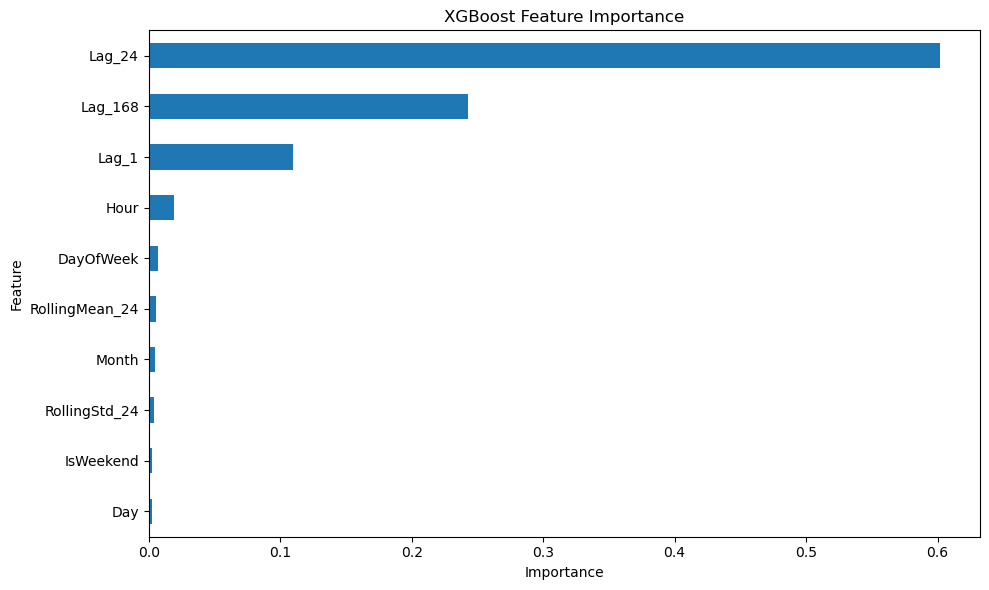

In [59]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [60]:
results.to_csv(
    "forecast_results.csv",
    index=False
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [61]:
import joblib

In [62]:
joblib.dump(
    model,
    "xgboost_electricity_forecasting_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [63]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(feature_importance)

Lag_24            0.602201
Lag_168           0.242961
Lag_1             0.109680
Hour              0.018843
DayOfWeek         0.006645
RollingMean_24    0.005562
Month             0.004675
RollingStd_24     0.004196
IsWeekend         0.002707
Day               0.002529
dtype: float32


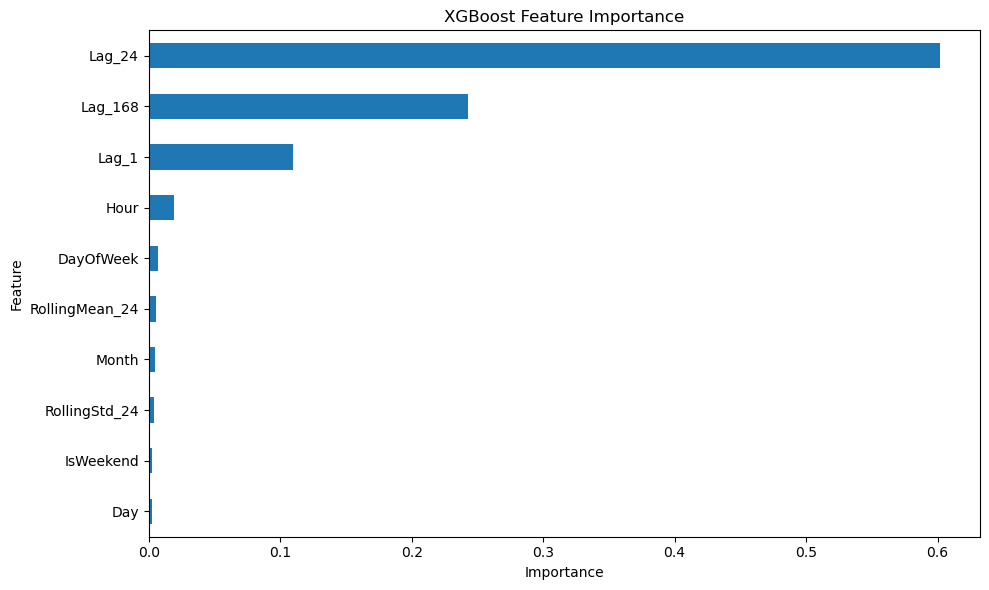

In [64]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(
    kind="barh"
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [65]:
results["Residual"] = (
    results["Actual"] - results["Predicted"]
)

results["Absolute_Residual"] = (
    results["Residual"].abs()
)

results.head()

,DateTime,Actual,Predicted,Error,Absolute_Error,Residual,Absolute_Residual
0,2017-10-20 19:00:00,44637.899343,45326.398438,-688.499094,688.499094,-688.499094,688.499094
1,2017-10-20 20:00:00,43882.713347,44456.085938,-573.372591,573.372591,-573.372591,573.372591
2,2017-10-20 21:00:00,41498.468270,41149.867188,348.601083,348.601083,348.601083,348.601083
3,2017-10-20 22:00:00,37074.485777,36107.480469,967.005308,967.005308,967.005308,967.005308
4,2017-10-20 23:00:00,31948.884027,31519.789062,429.094964,429.094964,429.094964,429.094964


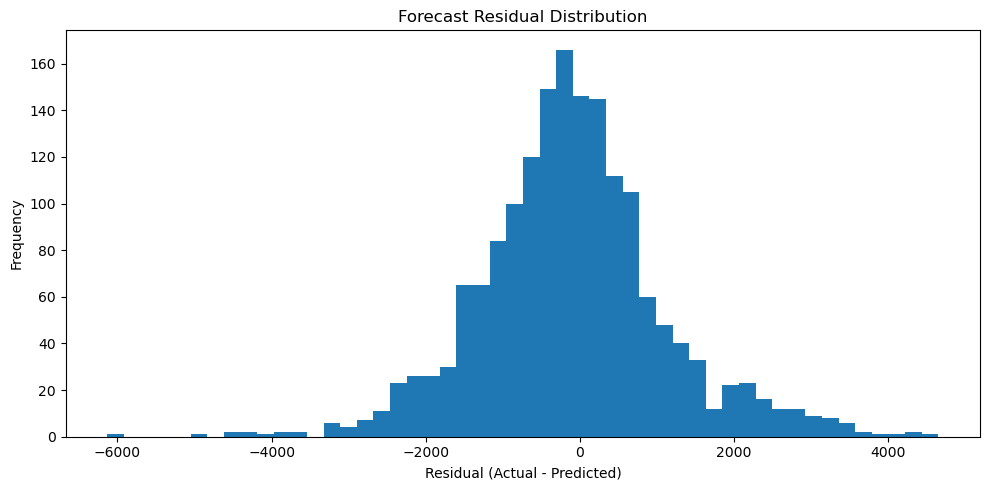

In [66]:
plt.figure(figsize=(10, 5))

plt.hist(
    results["Residual"],
    bins=50
)

plt.title("Forecast Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [67]:
print(results["Residual"].describe())

count    1709.000000
mean     -104.571138
std      1213.604845
min     -6130.214164
25%      -788.022820
50%      -146.028222
75%       517.664000
max      4654.755244
Name: Residual, dtype: float64


In [68]:
print("========== FORECASTING SUMMARY ==========")

print(f"Target: {target}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

print("\nXGBoost Performance:")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")

print("\nBaseline Performance:")
print(f"MAE  : {baseline_mae:.2f}")
print(f"RMSE : {baseline_rmse:.2f}")
print(f"MAPE : {baseline_mape:.2f}%")

print("\nModel file:")
print("xgboost_electricity_forecasting_model.pkl")

print("\nForecasting module completed successfully!")

========== FORECASTING SUMMARY ==========
Target: Zone 1 Power Consumption
Training samples: 6835
Testing samples: 1709

XGBoost Performance:
MAE  : 903.72
RMSE : 1217.75
MAPE : 3.15%

Baseline Performance:
MAE  : 968.40
RMSE : 1455.87
MAPE : 3.35%

Model file:
xgboost_electricity_forecasting_model.pkl

Forecasting module completed successfully!
